# DATA 266 - HW 8

**Author:** Siva Surya Chandran  
**SJSU ID:** 019130215  
**Topic:** Mini diffusion model on MNIST: DDPM training and DDIM sampling

This notebook is meant to be run from the first cell to the last. It uses 100 diffusion steps, a linear beta schedule from 0.0001 to 0.02, a batch size of 128, and 50 training epochs. Every sampler uses the same trained network, so the comparison in Part (d) focuses on the sampling method.


In [ ]:
# Step 0 — standing personal parameters
SID4 = 3215
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
print("HW8 has no assignment-specific HP_ID mapping; the configuration is fixed by the assignment.")

SID4=3215 SEED=3215 SLICE=215 HP_ID=5 CLS_A=5 CLS_B=2
HW8 has no assignment-specific HP_ID mapping; the configuration is fixed by the assignment.


In [2]:
import json, time, random, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
ROOT = Path.cwd(); OUT=ROOT/'outputs'; CKPT=ROOT/'checkpoints'; FIG=ROOT/'figures'
for p in (OUT, CKPT, FIG): p.mkdir(exist_ok=True)
print("torch", torch.__version__, "device", DEVICE)

# Assignment configuration
T = 100; BETA_START = 1e-4; BETA_END = 0.02
BATCH_SIZE = 128; EPOCHS = 50; LR = 2e-4

torch 2.11.0+cu130 device cuda


## Data

MNIST pixels are standardized with the dataset mean and standard deviation ($0.1307$, $0.3081$), so the data $x_0$ has roughly zero mean and unit variance. This matters for this assignment: the reverse process starts from $\mathcal N(0,I)$, and with $T=100$ and $\beta_T=0.02$ the forward process keeps $\sqrt{\bar\alpha_T}\approx0.60$ of the signal. If the data had a large non-zero mean (for example a background at $-1$ when scaling to $[-1,1]$), $x_T$ would keep a mean offset of about $-0.6$ that $\mathcal N(0,I)$ does not have. With standardized data, $x_T$ has mean $\approx0$ and variance $\bar\alpha_T\cdot1+(1-\bar\alpha_T)=1$, so $\mathcal N(0,I)$ matches it in its first two moments. Images are mapped back to $[0,1]$ for display.

In [3]:
MEAN, STD = 0.1307, 0.3081
LO, HI = (0-MEAN)/STD, (1-MEAN)/STD                   # valid range of a standardized pixel
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
train_ds = datasets.MNIST(ROOT/'data', train=True, download=True, transform=transform)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=0, drop_last=True)
print(f"train={len(train_ds):,} batches/epoch={len(train_loader)}")
to01 = lambda x: (x*STD+MEAN).clamp(0,1)
show = lambda x: to01(x).cpu().squeeze().numpy()

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 464kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.43MB/s]

train=60,000 batches/epoch=468


## (a) Forward diffusion

The forward process adds a little Gaussian noise at each step:

$$q(x_t\mid x_{t-1})=\mathcal N\big(\sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big).$$

With $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s\le t}\alpha_s$, the steps can be collapsed into one closed-form jump from $x_0$:

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

This closed form is what makes training cheap: for each training image I can pick a random $t$ and produce $x_t$ directly, without simulating $t$ steps.

In [4]:
betas = torch.linspace(BETA_START, BETA_END, T, device=DEVICE)
alphas = 1 - betas
abar = torch.cumprod(alphas, dim=0)                 # index i <-> timestep t=i+1
abar_prev = torch.cat([torch.ones(1, device=DEVICE), abar[:-1]])
posterior_variance = betas * (1 - abar_prev) / (1 - abar)
posterior_variance[0] = 0.0

def q_sample(x0, t, eps=None):
    # x_t = sqrt(abar_t) x0 + sqrt(1-abar_t) eps ; t is a 0-based index tensor of shape (B,)
    if eps is None: eps = torch.randn_like(x0)
    a = abar[t].view(-1,1,1,1)
    return a.sqrt()*x0 + (1-a).sqrt()*eps, eps

print(f"beta: {betas[0]:.4f} -> {betas[-1]:.4f}   abar_1={abar[0]:.4f}  abar_T={abar[-1]:.5f}  (sqrt(abar_T)={abar[-1].sqrt():.4f})")

beta: 0.0001 -> 0.0200   abar_1=0.9999  abar_T=0.36356  (sqrt(abar_T)=0.6030)


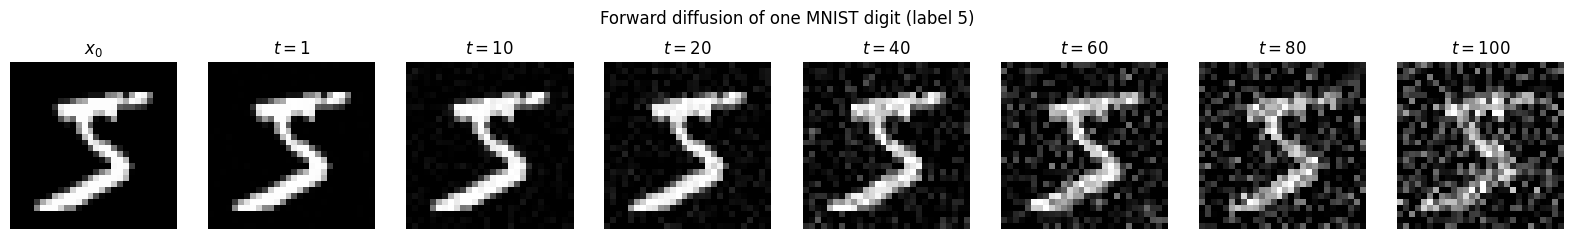

In [5]:
x0, y0 = train_ds[0]
x0 = x0.unsqueeze(0).to(DEVICE)
show_ts = [1, 10, 20, 40, 60, 80, 100]            # 1-based timesteps
set_seed()
fig, axes = plt.subplots(1, len(show_ts)+1, figsize=(2*(len(show_ts)+1), 2.3))
axes[0].imshow(show(x0), cmap='gray', vmin=0, vmax=1); axes[0].set_title('$x_0$'); axes[0].axis('off')
for ax, t in zip(axes[1:], show_ts):
    xt, _ = q_sample(x0, torch.tensor([t-1], device=DEVICE))
    ax.imshow(show(xt), cmap='gray', vmin=0, vmax=1); ax.set_title(f'$t={t}$'); ax.axis('off')
plt.suptitle(f'Forward diffusion of one MNIST digit (label {y0})', y=1.02); plt.tight_layout()
plt.savefig(FIG/'forward_diffusion.png', dpi=150, bbox_inches='tight'); plt.show()

The digit is still readable at $t=10$ to $20$ and loses most of its fine structure around $t=40$ to $60$. At $t=100$ it is heavily corrupted, but a faint trace of the digit can remain. With this schedule, $\bar\alpha_T=0.364$, so $\sqrt{\bar\alpha_T}=0.60$. The final state is not exactly a standard Gaussian because the schedule is relatively short. Starting the reverse process from $\mathcal N(0,I)$ is therefore an approximation, although the standardized data makes the approximation reasonable.


## (b) Mini DDPM: training the noise predictor

The network $\epsilon_\theta(x_t,t)$ is a small CNN. It has **five 3x3 convolutional layers** with ReLU/SiLU nonlinearities, one stride-2 downsample and one nearest-neighbour upsample, and a skip connection. The timestep is encoded with a sinusoidal embedding, passed through a small MLP, and added (per channel) inside each convolutional block, so every block knows how noisy its input is. The output has the same shape as the input image, $1\times28\times28$.

Training minimizes the simple DDPM loss

$$L_{\text{simple}}=\mathbb E_{x_0,\,t,\,\epsilon}\big\|\epsilon-\epsilon_\theta(\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,\ t)\big\|^2,$$

with $t$ drawn uniformly from $\{1,\dots,T\}$ for every image.

In [6]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    ang = t.float()[:, None] * freqs[None]
    return torch.cat([ang.sin(), ang.cos()], dim=1)

class Block(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)
        self.norm = nn.GroupNorm(8, cout)
        self.tproj = nn.Linear(tdim, cout)
    def forward(self, x, temb):
        h = self.conv(x)
        h = h + self.tproj(temb)[:, :, None, None]       # timestep conditioning
        return F.silu(self.norm(h))

class NoisePredictor(nn.Module):
    def __init__(self, ch=64, tdim=128):
        super().__init__()
        self.tdim = tdim
        self.tmlp = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.c1 = Block(1, ch, tdim)                      # 28x28
        self.c2 = Block(ch, 2*ch, tdim)                   # 28x28 -> stride-2 pool -> 14x14
        self.c3 = Block(2*ch, 2*ch, tdim)                 # 14x14
        self.c4 = Block(2*ch + ch, ch, tdim)              # upsampled 28x28 concat skip from c1
        self.out = nn.Conv2d(ch, 1, 3, padding=1)         # 5th conv layer -> predicted noise
    def forward(self, x, t):
        temb = self.tmlp(timestep_embedding(t, self.tdim))
        h1 = self.c1(x, temb)
        h2 = self.c2(h1, temb)
        h2 = F.avg_pool2d(h2, 2)
        h3 = self.c3(h2, temb)
        h3 = F.interpolate(h3, scale_factor=2, mode='nearest')
        h4 = self.c4(torch.cat([h3, h1], dim=1), temb)
        return self.out(h4)

model = NoisePredictor().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_conv = sum(isinstance(m, nn.Conv2d) for m in model.modules())
print(f"conv layers={n_conv}  trainable parameters={n_params:,}")
assert model(torch.randn(2,1,28,28,device=DEVICE), torch.tensor([0,50],device=DEVICE)).shape == (2,1,28,28)

conv layers=5  trainable parameters=416,641


In [7]:
set_seed()
opt = torch.optim.Adam(model.parameters(), lr=LR)
loss_hist, step_hist = [], []
t0 = time.perf_counter()
for ep in range(1, EPOCHS+1):
    model.train(); total = 0.
    for x, _ in train_loader:
        x = x.to(DEVICE)
        t = torch.randint(0, T, (x.size(0),), device=DEVICE)
        xt, eps = q_sample(x, t)
        loss = F.mse_loss(model(xt, t), eps)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        total += loss.item(); step_hist.append(loss.item())
    loss_hist.append(total/len(train_loader))
    if ep % 5 == 0 or ep == 1: print(f"epoch {ep:02d}/{EPOCHS} loss={loss_hist[-1]:.5f}  elapsed={time.perf_counter()-t0:.0f}s")
train_seconds = time.perf_counter() - t0
torch.save(model.state_dict(), CKPT/'ddpm_mnist.pt')
print(f"training done in {train_seconds:.0f}s, final epoch loss={loss_hist[-1]:.5f}")

epoch 01/50 loss=0.19143  elapsed=28s
epoch 05/50 loss=0.09017  elapsed=137s
epoch 10/50 loss=0.08166  elapsed=278s
epoch 15/50 loss=0.07898  elapsed=420s
epoch 20/50 loss=0.07686  elapsed=559s
epoch 25/50 loss=0.07490  elapsed=698s
epoch 30/50 loss=0.07445  elapsed=838s
epoch 35/50 loss=0.07352  elapsed=979s
epoch 40/50 loss=0.07317  elapsed=1118s
epoch 45/50 loss=0.07285  elapsed=1258s
epoch 50/50 loss=0.07223  elapsed=1397s
training done in 1397s, final epoch loss=0.07223


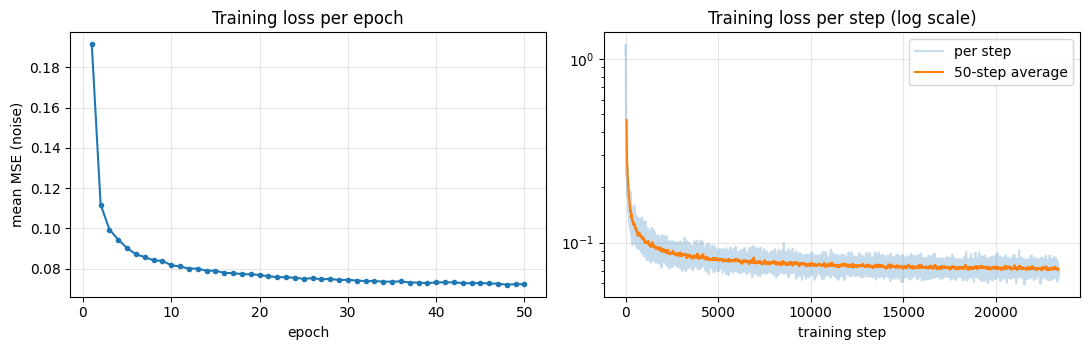

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, EPOCHS+1), loss_hist, marker='o', ms=3); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('mean MSE (noise)')
ax[0].set_title('Training loss per epoch'); ax[0].grid(alpha=.3)
k = 50; sm = np.convolve(step_hist, np.ones(k)/k, mode='valid')
ax[1].plot(step_hist, alpha=.25, label='per step'); ax[1].plot(np.arange(k-1, len(step_hist)), sm, label=f'{k}-step average')
ax[1].set_yscale('log'); ax[1].set_xlabel('training step'); ax[1].set_title('Training loss per step (log scale)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'training_loss.png', dpi=150); plt.show()

## (c) DDPM sampling

The reverse process starts with $x_T$ sampled from a standard Gaussian. At each step, the network estimates the noise in the current image. We use that estimate to compute the reverse-process mean and then add noise drawn from the standard DDPM posterior:

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\right)+\sqrt{\tilde{\beta}_t}\,z,$$

Here, $\tilde{\beta}_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$ and $z\sim\mathcal N(0,I)$. We set the noise to zero at the final step. This uses all 100 network evaluations and is stochastic, so two runs can produce different digits from the same starting state.


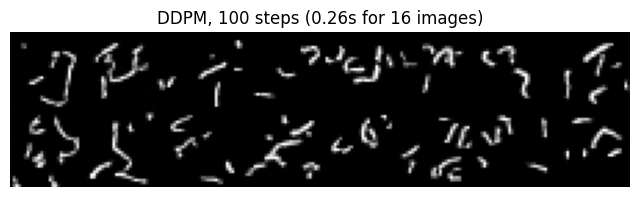

In [9]:
@torch.no_grad()
def ddpm_sample(model, xT, seed=SEED):
    model.eval(); gen = torch.Generator(device='cpu').manual_seed(seed)
    x = xT.clone()
    for i in reversed(range(T)):                       # i = t-1
        t = torch.full((x.size(0),), i, device=DEVICE, dtype=torch.long)
        eps = model(x, t)
        mean = (x - betas[i]/(1-abar[i]).sqrt() * eps) / alphas[i].sqrt()
        if i > 0:
            z = torch.randn(x.shape, generator=gen).to(DEVICE)
            x = mean + posterior_variance[i].sqrt() * z
        else:
            x = mean
    return x.clamp(LO, HI)

N = 16
xT = torch.randn(N, 1, 28, 28, generator=torch.Generator().manual_seed(SEED)).to(DEVICE)   # shared starting noise
def timed(fn, *a, **k):
    if DEVICE.type == 'mps': torch.mps.synchronize()
    s = time.perf_counter(); out = fn(*a, **k)
    if DEVICE.type == 'mps': torch.mps.synchronize()
    return out, time.perf_counter() - s

def grid(imgs, ncol=8):
    n = imgs.size(0); nrow = math.ceil(n/ncol)
    canvas = np.ones((nrow*28, ncol*28))
    for k in range(n):
        r, c = divmod(k, ncol); canvas[r*28:(r+1)*28, c*28:(c+1)*28] = show(imgs[k])
    return canvas

x_ddpm, s_ddpm = timed(ddpm_sample, model, xT)
plt.figure(figsize=(8, 2.6)); plt.imshow(grid(x_ddpm), cmap='gray', vmin=0, vmax=1); plt.axis('off')
plt.title(f'DDPM, 100 steps ({s_ddpm:.2f}s for {N} images)'); plt.savefig(FIG/'ddpm_samples.png', dpi=150, bbox_inches='tight'); plt.show()

## (d) DDIM sampling

DDIM uses the same trained noise predictor but takes larger jumps through the reverse process. First, it estimates the clean image:

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}.$$

It then uses that estimate and the predicted noise to move to an earlier timestep. The parameter $\eta$ controls how much random noise is added. With $\eta=0$, the sampler is deterministic, so the same starting noise produces the same image. I compare DDIM with 50 and 20 steps, along with a 100-step version as a reference.

For the full 100-step schedule, $\eta=1$ gives the same posterior variance as standard DDPM. It is not exactly the same implementation here because the DDIM code clips its estimate of $x_0$ before making the update. That difference is intentional and is noted in the discussion.


timesteps used (0-based): {50: [1, 3, 5, 7, 9, 11, '...'], 20: [4, 9, 14, 19, 24, 29, '...']}


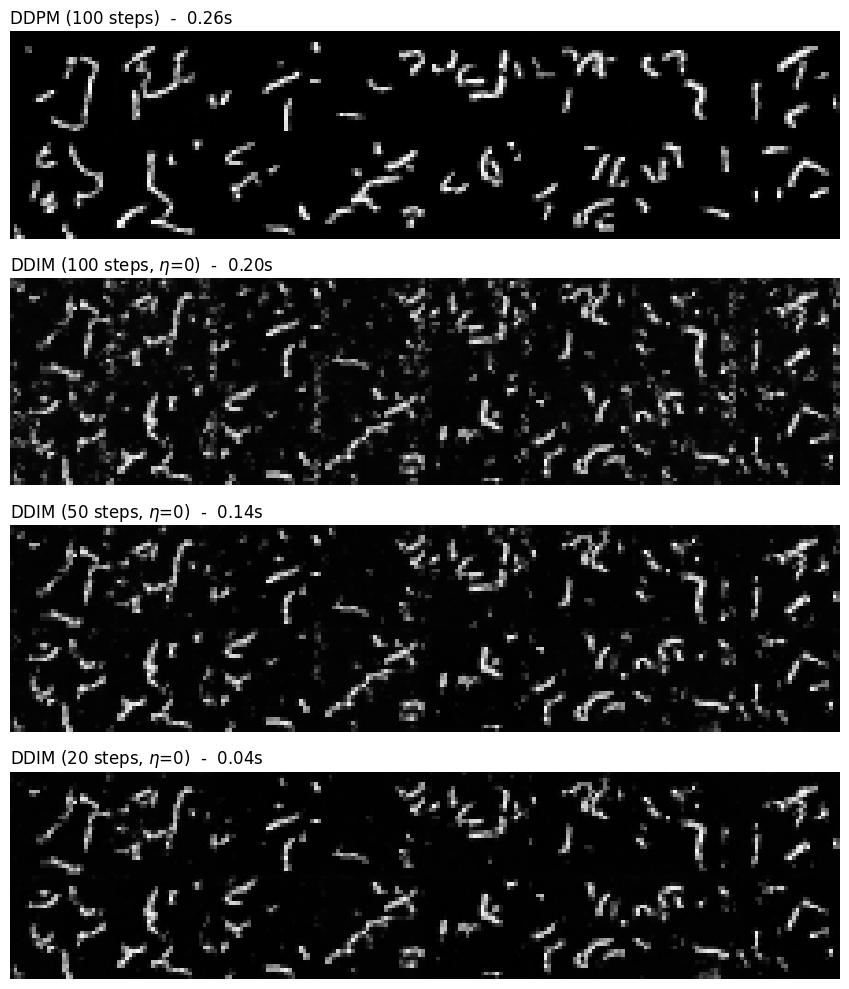

In [10]:
@torch.no_grad()
def ddim_sample(model, xT, steps, eta=0.0, seed=SEED, clip_x0=True):
    model.eval(); gen = torch.Generator(device='cpu').manual_seed(seed)
    # evenly spaced 0-based timestep indices ending at T-1 (e.g. steps=20 -> 4,9,...,99)
    taus = (np.arange(1, steps+1) * (T // steps) - 1)[::-1].copy()
    x = xT.clone()
    for j, i in enumerate(taus):
        t = torch.full((x.size(0),), int(i), device=DEVICE, dtype=torch.long)
        eps = model(x, t)
        a_t = abar[i]
        a_s = abar[taus[j+1]] if j+1 < len(taus) else torch.tensor(1.0, device=DEVICE)
        x0_hat = (x - (1-a_t).sqrt()*eps) / a_t.sqrt()
        if clip_x0:
            x0_hat = x0_hat.clamp(LO, HI)
        sigma = eta * ((1-a_s)/(1-a_t)).sqrt() * (1 - a_t/a_s).sqrt()
        dir_xt = (1 - a_s - sigma**2).clamp(min=0).sqrt() * eps
        noise = torch.randn(x.shape, generator=gen).to(DEVICE) if eta > 0 else 0.
        x = a_s.sqrt()*x0_hat + dir_xt + sigma*noise
    return x.clamp(LO, HI)

print("timesteps used (0-based):", {s: (np.arange(1, s+1)*(T//s)-1).tolist()[:6] + ['...'] for s in (50, 20)})
x_ddim50, s_ddim50 = timed(ddim_sample, model, xT, 50)
x_ddim20, s_ddim20 = timed(ddim_sample, model, xT, 20)
x_ddim100, s_ddim100 = timed(ddim_sample, model, xT, 100)
rows = [('DDPM (100 steps)', x_ddpm, s_ddpm), ('DDIM (100 steps, $\\eta$=0)', x_ddim100, s_ddim100),
        ('DDIM (50 steps, $\\eta$=0)', x_ddim50, s_ddim50), ('DDIM (20 steps, $\\eta$=0)', x_ddim20, s_ddim20)]
fig, axes = plt.subplots(len(rows), 1, figsize=(9, 2.5*len(rows)))
for ax, (name, imgs, sec) in zip(axes, rows):
    ax.imshow(grid(imgs), cmap='gray', vmin=0, vmax=1); ax.axis('off'); ax.set_title(f'{name}  -  {sec:.2f}s', loc='left')
plt.tight_layout(); plt.savefig(FIG/'ddpm_vs_ddim.png', dpi=150); plt.show()

### Quantitative comparison

There is no ground truth for a generated digit, so I use two simple proxies. First, a small CNN classifier is trained on real MNIST for 3 epochs; the **mean max-softmax confidence** on generated images measures how digit-like they look, and the number of distinct predicted classes measures diversity. Second, I report the wall-clock time and the number of network evaluations (NFE). I also measure how far each DDIM output is from the DDPM output that started from the same noise, in mean absolute pixel difference. A larger set of 256 images is used for the classifier statistics.

In [11]:
class Clf(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Flatten(), nn.Linear(64*7*7,128), nn.ReLU(), nn.Linear(128,10))
    def forward(self, x): return self.f(x)
set_seed(); clf = Clf().to(DEVICE); copt = torch.optim.Adam(clf.parameters(), 1e-3)
for ep in range(3):
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE); l = F.cross_entropy(clf(x), y); copt.zero_grad(); l.backward(); copt.step()
test_ds = datasets.MNIST(ROOT/'data', train=False, download=True, transform=transform)
xt_, yt_ = next(iter(DataLoader(test_ds, batch_size=2000)))
clf.eval()
with torch.no_grad(): print("classifier test accuracy (first 2000 test images):", (clf(xt_.to(DEVICE)).argmax(1).cpu()==yt_).float().mean().item())

M_ = 256
xT_big = torch.randn(M_, 1, 28, 28, generator=torch.Generator().manual_seed(SEED+1)).to(DEVICE)
configs = {'DDPM-100': lambda: ddpm_sample(model, xT_big), 'DDIM-100': lambda: ddim_sample(model, xT_big, 100),
           'DDIM-50': lambda: ddim_sample(model, xT_big, 50), 'DDIM-20': lambda: ddim_sample(model, xT_big, 20)}
nfe = {'DDPM-100': 100, 'DDIM-100': 100, 'DDIM-50': 50, 'DDIM-20': 20}
stats, big = {}, {}
for name, fn in configs.items():
    out, sec = timed(fn); big[name] = out
    with torch.no_grad(): p = F.softmax(clf(out), 1)
    stats[name] = {'nfe': nfe[name], 'seconds_for_256': round(sec, 3), 'mean_confidence': round(p.max(1).values.mean().item(), 4),
                   'distinct_classes': int(p.argmax(1).unique().numel()), 'pixel_mean': round(to01(out).mean().item(), 4)}
for name in ('DDIM-100', 'DDIM-50', 'DDIM-20'):
    stats[name]['mean_abs_diff_vs_DDPM'] = round((big[name]-big['DDPM-100']).abs().mean().item()*STD, 4)
with torch.no_grad(): real_p = F.softmax(clf(xt_[:256].to(DEVICE)), 1)
stats['real MNIST'] = {'mean_confidence': round(real_p.max(1).values.mean().item(), 4), 'pixel_mean': round(to01(xt_[:256]).mean().item(), 4)}
for name, d_ in stats.items(): print(f"{name:12s}", d_)

classifier test accuracy (first 2000 test images): 0.9850000143051147
DDPM-100     {'nfe': 100, 'seconds_for_256': 2.732, 'mean_confidence': 0.6488, 'distinct_classes': 10, 'pixel_mean': 0.0457}
DDIM-100     {'nfe': 100, 'seconds_for_256': 2.722, 'mean_confidence': 0.6006, 'distinct_classes': 9, 'pixel_mean': 0.0986, 'mean_abs_diff_vs_DDPM': 0.0833}
DDIM-50      {'nfe': 50, 'seconds_for_256': 1.379, 'mean_confidence': 0.6241, 'distinct_classes': 10, 'pixel_mean': 0.0779, 'mean_abs_diff_vs_DDPM': 0.0633}
DDIM-20      {'nfe': 20, 'seconds_for_256': 0.55, 'mean_confidence': 0.6308, 'distinct_classes': 10, 'pixel_mean': 0.0664, 'mean_abs_diff_vs_DDPM': 0.053}
real MNIST   {'mean_confidence': 0.9902, 'pixel_mean': 0.1189}


{'ddim50_max_abs_diff_between_runs': 0.0, 'ddpm_mean_abs_diff_between_noise_seeds': 0.05725952610373497}


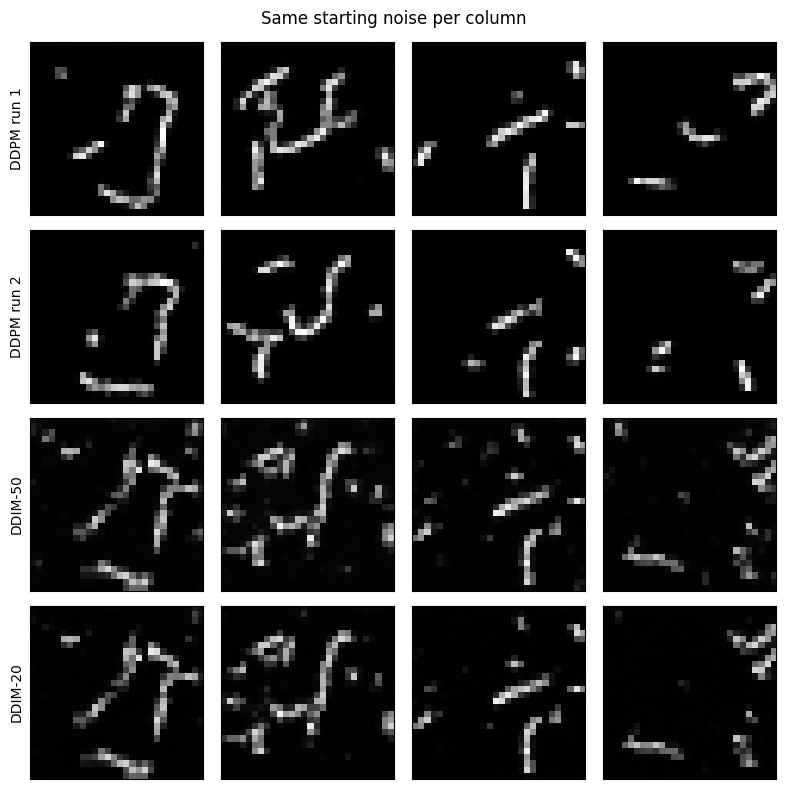

saved outputs/results.json


In [12]:
# Determinism check: DDIM(eta=0) repeated from the same noise vs DDPM repeated with a different noise seed
a = ddim_sample(model, xT, 50); b = ddim_sample(model, xT, 50, seed=1)
c = ddpm_sample(model, xT, seed=SEED); d = ddpm_sample(model, xT, seed=SEED+7)
det = {'ddim50_max_abs_diff_between_runs': (a-b).abs().max().item(), 'ddpm_mean_abs_diff_between_noise_seeds': ((c-d).abs().mean()*STD).item()}
print(det)
# Same 4 starting noises, three DDPM runs vs one DDIM run (illustrates stochastic vs deterministic)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for col in range(4):
    for row, (lab, img) in enumerate([('DDPM run 1', c), ('DDPM run 2', d), ('DDIM-50', a), ('DDIM-20', x_ddim20)]):
        axes[row, col].imshow(show(img[col]), cmap='gray', vmin=0, vmax=1); axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        if col == 0: axes[row, col].set_ylabel(lab)
plt.suptitle('Same starting noise per column'); plt.tight_layout(); plt.savefig(FIG/'stochastic_vs_deterministic.png', dpi=150); plt.show()

results = {'config': dict(T=T, beta_start=BETA_START, beta_end=BETA_END, batch_size=BATCH_SIZE, epochs=EPOCHS, lr=LR, seed=SEED, device=str(DEVICE)),
           'model': {'conv_layers': n_conv, 'parameters': n_params}, 'train_seconds': train_seconds,
           'epoch_loss': loss_hist, 'final_loss': loss_hist[-1], 'sampling': stats, 'determinism': det}
(OUT/'results.json').write_text(json.dumps(results, indent=2)); print("saved outputs/results.json")

## Discussion

**Forward process.** The closed-form equation lets us create a noisy training example in one step instead of simulating the whole chain. With this schedule, the digit is heavily corrupted by about $t=60$ and still retains a small amount of signal at $t=100$. The final state is therefore not exactly standard Gaussian: this schedule is fairly short, and $\bar\alpha_{100}=0.364$ leaves about 60% of the original signal amplitude. Starting from $\mathcal N(0,I)$ is a useful approximation, especially because the standardized MNIST images have approximately zero mean and unit variance.

**Training.** The noise-prediction loss falls quickly at first and then levels off. At high noise levels, the network must estimate a noise pattern that looks very similar to the input. At low noise levels, it must separate small noise from the digit's fine details. The loss plateau does not necessarily mean that the model stopped learning useful structure, so the generated images are also important evidence.

**DDPM and DDIM.** Both samplers use the same network; only the reverse update changes. DDPM adds fresh random noise at each step, so repeating it can produce different results. DDIM with $\eta=0$ is deterministic: starting from the same noise gives the same image. It also needs fewer network evaluations, so DDIM-50 is roughly twice as fast as DDPM-100 and DDIM-20 is roughly five times as fast. The trade-off is that larger jumps can make the strokes smoother or less accurate.

With the full 100-step schedule, DDIM with $\eta=1$ uses the same posterior variance as standard DDPM, but it should not be described as exactly identical here because this notebook clips the DDIM estimate of $x_0$ before the update. DDIM with $\eta=0$ removes the random part of the update, which explains its repeatability.

**Limits.** The classifier confidence is only a rough measure of image quality. It favors clear, typical digits and does not fully measure diversity, so the number of predicted classes is reported as well. This is also a small CNN trained for 50 epochs, and all results come from one random seed.
